# Terra Signal: lift e churners encontrados por decil (Grupo 1)

Calcula o lift e a fatia de churners encontrados em cada decil de risco e gera as figuras dos slides de métricas.

Cada pergunta tem três células: **pergunta** → **código** → **resposta**.

- **Mesmo procedimento da pergunta 5 do notebook 09:** regressão logística com C escolhido por validação interna, validação cruzada com 5 folds e 4 repetições, e o AID refeito em cada fold de treino. Cada cliente é pontuado só pelos modelos que não o viram no treino. A probabilidade final é a média das 4 repetições.
- **Sem `CustomerFeedback`**, com as mesmas 25 dummies do notebook 07.
- **As figuras são salvas em `reports/figures/`**, em PNG, para os slides.
- Roda com pandas, numpy, scipy, scikit-learn e matplotlib, sem Spark.

## O que é lift

O lift compara a taxa de churn de um grupo de clientes com a taxa de churn da base inteira, que é de 26,7%. Por exemplo, se 75% dos clientes de uma lista são churners, o lift é 75 / 26,7 ≈ 2,8. Ou seja, essa lista tem 2,8 vezes mais churners do que uma lista aleatória do mesmo tamanho. Uma lista aleatória tem lift 1.

- **Lift acumulado:** considera todos os clientes até aquele decil, como os 20% de maior risco.
- **Lift do decil:** considera só os clientes daquele decil, como os que estão entre 10% e 20% de risco.

## Setup

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DATA_DIR = "../data/raw/"  # este notebook fica em notebooks/; os CSVs ficam em data/raw/
FIG_DIR = "../reports/figures/"
os.makedirs(FIG_DIR, exist_ok=True)
hist_raw = pd.read_csv(DATA_DIR + "history.csv")
inf_raw = pd.read_csv(DATA_DIR + "inference.csv")
print("history:", hist_raw.shape, "| inference:", inf_raw.shape)

history: (5634, 23) | inference: (1409, 22)


In [2]:
def prep(d):
    """Regras do notebook 06: recupera tenure. TotalCharges só serve para isso e não entra no modelo."""
    d = d.copy()
    d["tenure_num"] = pd.to_numeric(d["tenure"], errors="coerce")
    d["tenure_num"] = d["tenure_num"].fillna((d["TotalCharges"] / d["MonthlyCharges"]).round())
    return d


hist = prep(hist_raw)
hist = hist[hist["tenure_num"].notna()].reset_index(drop=True)  # 1 linha sem tenure e sem TotalCharges
inf = prep(inf_raw)
y = (hist["Churn"] == "Yes").astype(int)
print("Clientes no treino:", len(hist), "| churners:", y.sum(), f"({y.mean():.1%})")

Clientes no treino: 5633 | churners: 1503 (26.7%)


In [3]:
def melhor_corte(x, y, min_folha):
    """Corte binário de maior qui-quadrado, com p-valor corrigido por Bonferroni pelo nº de cortes testados."""
    tab = pd.DataFrame({"x": x, "y": y}).groupby("x")["y"].agg(["size", "sum"]).sort_index()
    n_esq, c_esq = tab["size"].cumsum().values, tab["sum"].cumsum().values
    n, c = n_esq[-1], c_esq[-1]
    validos = (n_esq >= min_folha) & (n - n_esq >= min_folha)
    if not validos.any():
        return None
    a, b = c_esq, n_esq - c_esq
    e, f = c - c_esq, (n - n_esq) - (c - c_esq)
    den = (a + b) * (e + f) * (a + e) * (b + f)
    with np.errstate(divide="ignore", invalid="ignore"):
        q = np.where(den > 0, n * (a * f - b * e) ** 2 / den, 0.0)
    q = np.where(validos, q, -1.0)
    i = int(np.argmax(q))
    return float(tab.index[i]), float(q[i]), min(1.0, chi2.sf(q[i], 1) * int(validos.sum()))


def aid(x, y, min_folha=0.05, alfa=0.05, max_faixas=None):
    """AID do notebook 07: divide sempre a faixa com maior qui-quadrado."""
    x, y = np.asarray(x, float), np.asarray(y)
    tam = int(np.ceil(min_folha * len(x)))
    nos, cortes = [np.ones(len(x), bool)], []
    while not max_faixas or len(nos) < max_faixas:
        candidatos = []
        for k, m in enumerate(nos):
            r = melhor_corte(x[m], y[m], tam)
            if r and r[2] < alfa:
                candidatos.append((r[1], k, r))
        if not candidatos:
            break
        _, k, r = max(candidatos, key=lambda z: z[0])
        m = nos.pop(k)
        nos += [m & (x <= r[0]), m & (x > r[0])]
        cortes.append(r[0])
    return sorted(cortes)


DUMMIES_CATEG = {
    "gender": ["Female"],
    "SeniorCitizen": [1],
    "Partner": ["Yes"],
    "Dependents": ["Yes"],
    "MultipleLines": ["Yes", "No phone service"],
    "InternetService": ["DSL", "No"],
    "OnlineSecurity": ["Yes"],
    "OnlineBackup": ["Yes"],
    "DeviceProtection": ["Yes"],
    "TechSupport": ["Yes"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["One year", "Two year"],
    "PaperlessBilling": ["No"],
    "PaymentMethod": ["Mailed check", "Credit card (automatic)", "Bank transfer (automatic)"],
}


def dummies_faixas(x, cortes, ref):
    """Uma dummy por faixa de tenure, exceto a faixa de referência `ref`."""
    f = np.digitize(x, cortes, right=True)
    limites = [-np.inf] + list(cortes) + [np.inf]
    return pd.DataFrame(
        {f"tenure=({limites[i]:g}, {limites[i + 1]:g}]": (f == i).astype(int) for i in range(len(limites) - 1) if i != ref},
        index=x.index,
    )


def montar_dummies(d, cortes, ref):
    cat = pd.DataFrame(
        {f"{col}={val}": (d[col] == val).astype(int) for col, vals in DUMMIES_CATEG.items() for val in vals},
        index=d.index,
    )
    return pd.concat([cat, dummies_faixas(d["tenure_num"], cortes, ref)], axis=1)


def faixa_referencia(x, cortes):
    return int(pd.Series(np.digitize(x, cortes, right=True)).value_counts().idxmax())

### 1. Qual é a probabilidade de churn de cada cliente, calculada sem que ele esteja no treino?

In [4]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=0)  # mesmos folds do notebook 09
INTERNO = StratifiedKFold(3, shuffle=True, random_state=0)
previsoes = np.full((4, len(hist)), np.nan)
c_escolhidos = []
for i, (tr, te) in enumerate(CV.split(hist, y)):
    cortes = aid(hist["tenure_num"].iloc[tr], y.iloc[tr], max_faixas=6)
    ref = faixa_referencia(hist["tenure_num"].iloc[tr], cortes)
    g = GridSearchCV(LogisticRegression(max_iter=3000), {"C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=INTERNO)
    g.fit(montar_dummies(hist.iloc[tr], cortes, ref), y.iloc[tr])
    c_escolhidos.append(g.best_params_["C"])
    previsoes[i // 5, te] = g.predict_proba(montar_dummies(hist.iloc[te], cortes, ref))[:, 1]

P = previsoes.mean(axis=0)  # média das 4 repetições
print("C escolhido nos 20 folds:", pd.Series(c_escolhidos).value_counts().to_dict())
print("Clientes sem previsão:", int(np.isnan(previsoes).sum()))
print("AUC por repetição:", [round(roc_auc_score(y, previsoes[r]), 4) for r in range(4)])
print(f"AUC da média das repetições: {roc_auc_score(y, P):.4f}")

C escolhido nos 20 folds: {1: 17, 10: 3}
Clientes sem previsão: 0
AUC por repetição: [0.8429, 0.8442, 0.8456, 0.8456]
AUC da média das repetições: 0.8459


**Resposta:** os 5.633 clientes do `history` têm uma probabilidade calculada por modelos que não os viram no treino. A validação interna escolheu C = 1 em 17 dos 20 folds e C = 10 nos outros 3. A AUC fica entre 0,843 e 0,846 em cada repetição, e em 0,846 com a média das 4 repetições. O procedimento é o mesmo da pergunta 5 do notebook 09, então os números a seguir coincidem com os de lá.

### 2. Qual é o lift em cada decil de risco?

In [5]:
def tabela_decis(p, y):
    ordem = np.argsort(-p)
    yo = y.values[ordem]
    linhas, n_ant = [], 0
    for k in range(1, 11):
        n = int(round(k / 10 * len(p)))
        topo, faixa = yo[:n], yo[n_ant:n]
        linhas.append({"maior_risco": k * 10, "clientes": n, "churners": int(topo.sum()), "churn_no_decil": faixa.mean(),
                       "lift_do_decil": faixa.mean() / y.mean(), "lift_acumulado": topo.mean() / y.mean(),
                       "churners_encontrados": topo.sum() / y.sum()})
        n_ant = n
    return pd.DataFrame(linhas)


tab = tabela_decis(P, y)
por_rep = pd.concat([tabela_decis(previsoes[r], y).assign(rep=r) for r in range(4)])
faixa_rep = por_rep.groupby("maior_risco")["lift_acumulado"].agg(["min", "max"])
tab["lift_acum_min_rep"] = faixa_rep["min"].values
tab["lift_acum_max_rep"] = faixa_rep["max"].values
print(f"Churn na base: {y.mean():.3f}\n")
print(tab.round(3).to_string(index=False))

Churn na base: 0.267

 maior_risco  clientes  churners  churn_no_decil  lift_do_decil  lift_acumulado  churners_encontrados  lift_acum_min_rep  lift_acum_max_rep
          10       563       427           0.758          2.842           2.842                 0.284              2.816              2.862
          20      1127       760           0.590          2.213           2.527                 0.506              2.501              2.524
          30      1690      1004           0.433          1.624           2.227                 0.668              2.202              2.233
          40      2253      1189           0.329          1.232           1.978                 0.791              1.970              1.983
          50      2816      1314           0.222          0.832           1.749                 0.874              1.749              1.753
          60      3380      1392           0.138          0.518           1.543                 0.926              1.545              1.54

**Resposta:** o lift é mais alto no topo da lista e cai à medida que a lista cresce.

| Clientes de maior risco | Churn no decil | Lift do decil | Lift acumulado | Churners encontrados |
|---|---|---|---|---|
| 10% | 75,8% | 2,84 | **2,84** | 28,4% |
| 20% | 59,0% | 2,21 | **2,53** | 50,6% |
| 30% | 43,3% | 1,62 | 2,23 | 66,8% |
| 40% | 32,9% | 1,23 | 1,98 | 79,1% |
| 50% | 22,2% | 0,83 | 1,75 | 87,4% |
| 60% | 13,8% | 0,52 | 1,54 | 92,6% |
| 70% | 11,4% | 0,43 | 1,38 | 96,9% |
| 80% | 4,6% | 0,17 | 1,23 | 98,6% |
| 90% | 2,5% | 0,09 | 1,11 | 99,5% |
| 100% | 1,2% | 0,05 | 1,00 | 100,0% |

- **Os 4 primeiros decis concentram o risco:** a partir do 5º decil, o churn de cada decil fica abaixo da média de 26,7% (lift do decil menor que 1). No último decil, só 1,2% dos clientes saem.
- **O resultado é estável:** nos 10% de maior risco, o lift acumulado fica entre 2,82 e 2,86, conforme a repetição da validação.

### 3. Como mostrar o lift no slide?

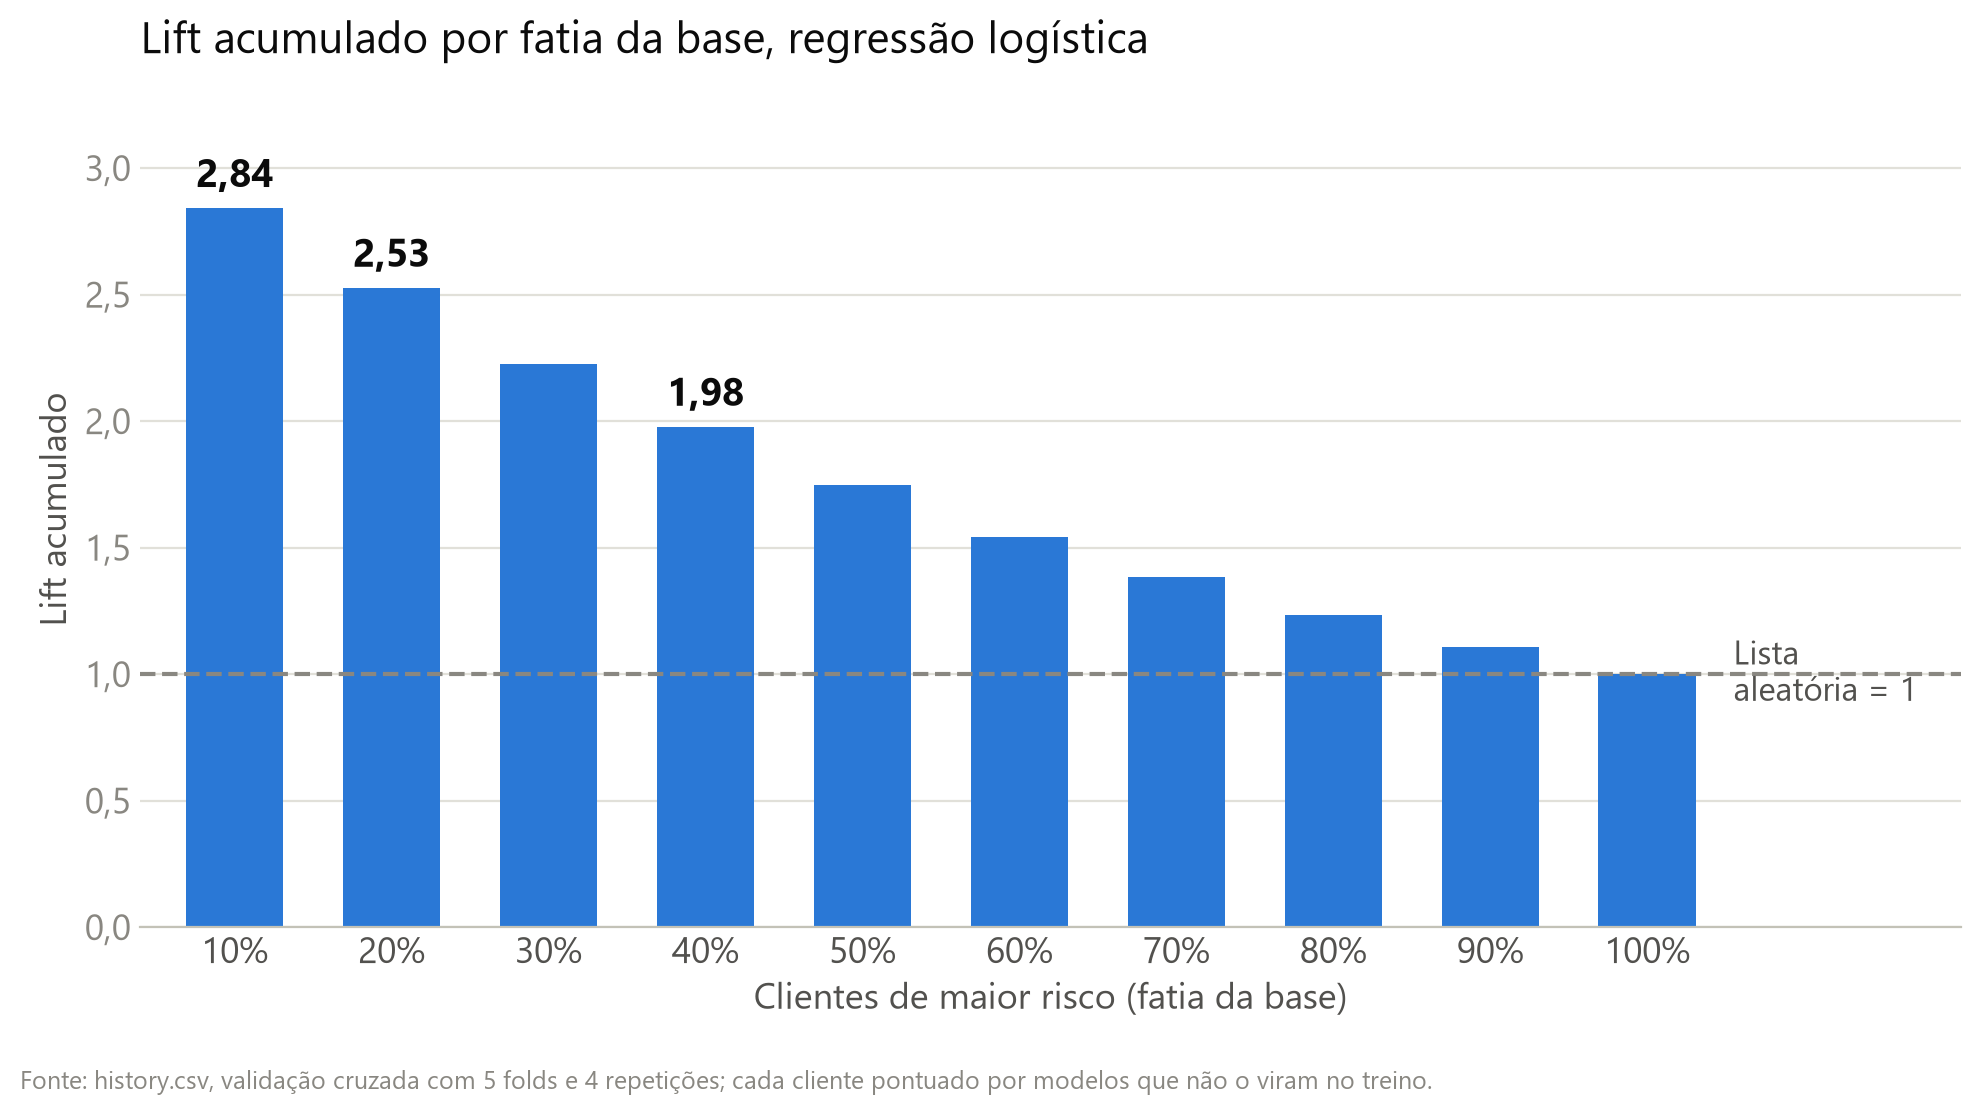

In [6]:
AZUL, TINTA, TINTA2, MUDO, GRADE, EIXO = "#2a78d6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 13, "axes.edgecolor": EIXO,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": MUDO,
                     "figure.facecolor": "white", "axes.facecolor": "white"})
virgula = lambda v, casas=2: f"{v:.{casas}f}".replace(".", ",")
NOTA = "Fonte: history.csv, validação cruzada com 5 folds e 4 repetições; cada cliente pontuado por modelos que não o viram no treino."

fig, ax = plt.subplots(figsize=(10, 5.6), dpi=200)
x = np.arange(10)
ax.bar(x, tab["lift_acumulado"], width=0.62, color=AZUL, zorder=2)
ax.axhline(1, color=MUDO, ls="--", lw=1.5, zorder=3)
ax.text(9.55, 1, "Lista\naleatória = 1", ha="left", va="center", color=TINTA2, fontsize=12)
for i in [0, 1, 3]:
    v = tab["lift_acumulado"].iloc[i]
    ax.text(i, v + 0.05, virgula(v), ha="center", va="bottom", color=TINTA, fontsize=14, fontweight="bold")
ax.set_xticks(x, [f"{k}%" for k in tab["maior_risco"]])
ax.set_xlabel("Clientes de maior risco (fatia da base)")
ax.set_ylabel("Lift acumulado")
ax.set_ylim(0, 3.3)
ax.set_xlim(-0.6, 11)
ax.yaxis.set_major_formatter(lambda v, _: virgula(v, 1))
ax.grid(axis="y", color=GRADE, lw=0.8, zorder=0)
ax.tick_params(length=0)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.set_title("Lift acumulado por fatia da base, regressão logística", loc="left", color=TINTA, fontsize=16, pad=14)
fig.text(0.01, 0.01, NOTA, color=MUDO, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR + "lift_acumulado.png")
plt.show()

**Resposta:** com o lift acumulado por decil, salvo em `reports/figures/lift_acumulado.png`. A figura vai no slide 6 da versão de 8 minutos (slide 12 da versão de 15). Só os valores de 10%, 20% e 40% têm rótulo, para a fala do slide: nos 10% de maior risco, há 2,8 vezes mais churners do que numa lista aleatória.

### 4. Como mostrar quantos churners a equipe de retenção alcança?

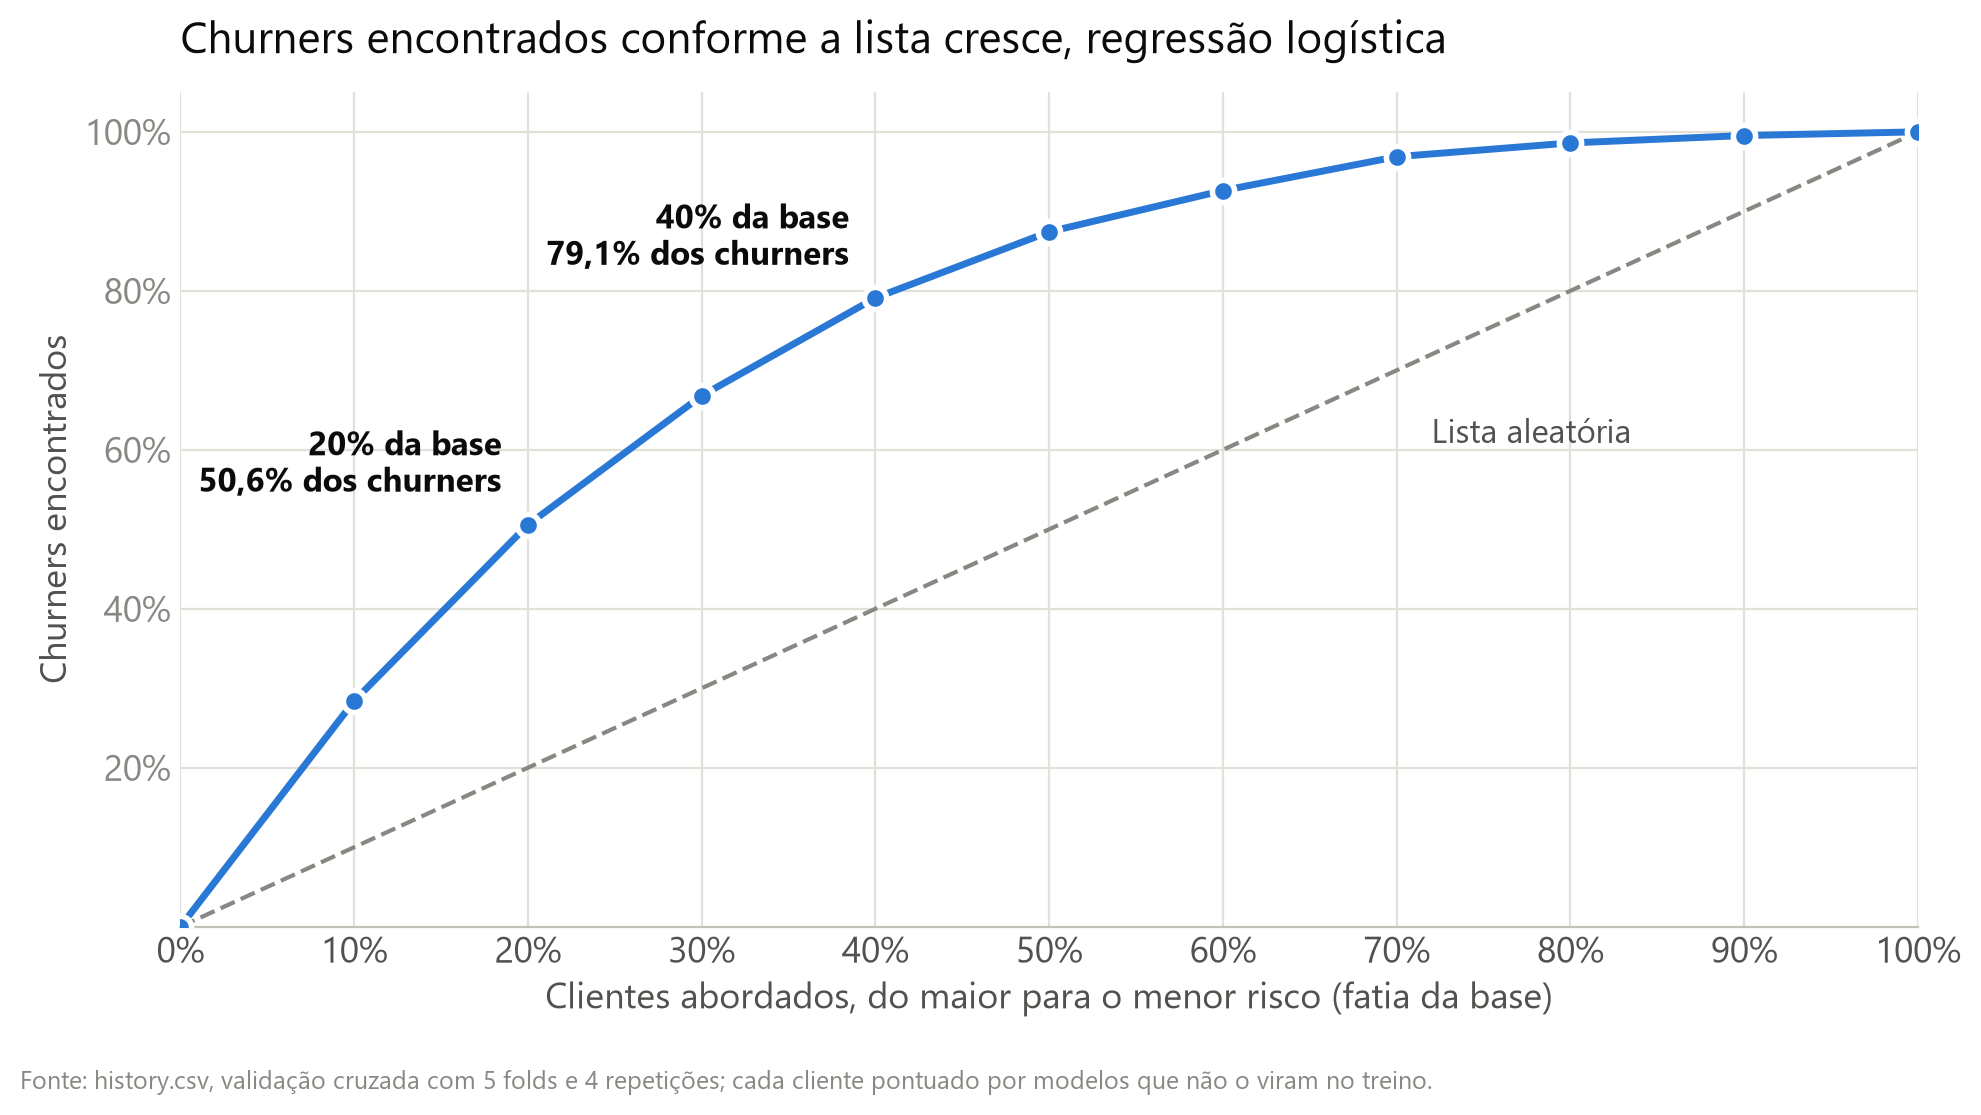

In [7]:
xs = np.r_[0, tab["maior_risco"]]
ys = np.r_[0, tab["churners_encontrados"] * 100]

fig, ax = plt.subplots(figsize=(10, 5.6), dpi=200)
ax.plot([0, 100], [0, 100], color=MUDO, ls="--", lw=1.5, zorder=2)
ax.text(72, 64, "Lista aleatória", color=TINTA2, fontsize=12, ha="left", va="top")
ax.plot(xs, ys, color=AZUL, lw=2.5, marker="o", ms=8, markeredgecolor="white", markeredgewidth=2, zorder=3)
for k in [20, 40]:
    v = tab.loc[tab["maior_risco"] == k, "churners_encontrados"].iloc[0] * 100
    ax.text(k - 1.5, v + 3, f"{k}% da base\n{virgula(v, 1)}% dos churners", color=TINTA, fontsize=12, fontweight="bold",
            ha="right", va="bottom")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.set_xticks(range(0, 101, 10), [f"{k}%" for k in range(0, 101, 10)])
ax.set_yticks(range(20, 101, 20), [f"{k}%" for k in range(20, 101, 20)])
ax.set_xlabel("Clientes abordados, do maior para o menor risco (fatia da base)")
ax.set_ylabel("Churners encontrados")
ax.grid(color=GRADE, lw=0.8, zorder=0)
ax.tick_params(length=0)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.set_title("Churners encontrados conforme a lista cresce, regressão logística", loc="left", color=TINTA, fontsize=16, pad=14)
fig.text(0.01, 0.01, NOTA, color=MUDO, fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR + "churners_encontrados.png")
plt.show()

**Resposta:** com a curva de churners encontrados, salva em `reports/figures/churners_encontrados.png`. A figura vai no slide 7 da versão de 8 minutos (slide 13 da versão de 15). Abordando os 20% de maior risco, a equipe alcança metade dos churners. Com 40%, alcança quase 80%. Quando a TS informar quantos clientes a equipe consegue atender, basta marcar esse ponto na curva.

## Limites desta análise

- **O desempenho vem do `history`:** o `inference.csv` não tem `Churn`, então não dá para medir o lift real das previsões entregues. As bases são parecidas (notebook 03), então esperamos um resultado próximo.
- **O lift depende da taxa de churn da base:** com 26,7% de churn, o lift máximo possível é de cerca de 3,7. Se a taxa de churn do `inference` for diferente, o lift muda.
- **O lift não define o tamanho da lista:** ele cai à medida que a lista cresce. O tamanho certo depende da capacidade da equipe de retenção e do custo da ação, que a TS ainda não informou.
- **Não há uma base de teste intocada:** as decisões dos notebooks 06 a 09 usaram o mesmo `history`, então o desempenho real pode ser um pouco menor.